# EDA

This notebook uses the training portion only. Keeping validation and test blocks separate prevents exploratory work from leaking into final evaluation.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

root = Path.cwd()
if not (root / 'datasets').exists():
    root = root.parent
raw = root / 'datasets' / 'hdfs_v1' / 'preprocessed'
processed = root / 'datasets' / 'processed'
figures = root / 'reports' / 'figures'

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(processed / 'hdfs_clean.csv')
splits = np.load(processed / 'splits.npz')
train = df.iloc[splits['train_idx']]
event_columns = [name for name in df.columns if name.startswith('E') and name[1:].isdigit()]
print(train.shape)
print(train.target.value_counts())


(345036, 31)
target
0    334933
1     10103
Name: count, dtype: int64


Mean, median, standard deviation, minimum, and maximum summarise event counts for normal and anomalous training blocks.

In [2]:
normal = train.loc[train.target == 0, event_columns]
anomaly = train.loc[train.target == 1, event_columns]
normal_stats = normal.agg(['mean', 'median', 'std', 'min', 'max']).T
anomaly_stats = anomaly.agg(['mean', 'median', 'std', 'min', 'max']).T
display(normal_stats)
display(anomaly_stats)


,mean,median,std,min,max
E1,0.000000,0.0,0.000000,0.0,0.0
E2,0.208591,0.0,0.580566,0.0,4.0
E3,0.746296,0.0,2.504043,0.0,203.0
E4,0.622498,0.0,1.612059,0.0,41.0
E5,3.004789,3.0,0.101231,3.0,12.0
E6,0.004789,0.0,0.101231,0.0,9.0
E7,0.000000,0.0,0.000000,0.0,0.0
E8,0.000000,0.0,0.000000,0.0,0.0
E9,3.000000,3.0,0.000000,3.0,3.0
E10,0.000000,0.0,0.000000,0.0,0.0


,mean,median,std,min,max
E1,0.000990,0.0,0.044484,0.0,2.0
E2,0.184401,0.0,0.563654,0.0,4.0
E3,0.681679,0.0,3.283302,0.0,203.0
E4,0.491735,0.0,1.369878,0.0,15.0
E5,2.721073,3.0,1.106933,1.0,8.0
E6,0.262694,0.0,0.562014,0.0,5.0
E7,0.200831,0.0,0.417342,0.0,5.0
E8,0.002277,0.0,0.049695,0.0,2.0
E9,1.887162,3.0,1.448358,0.0,3.0
E10,0.004454,0.0,0.084891,0.0,3.0


This table compares the class means and the share of blocks where each event is absent.

In [3]:
means = pd.DataFrame()
means['normal_mean'] = normal.mean()
means['anomaly_mean'] = anomaly.mean()
means['normal_absent'] = (normal == 0).mean()
means['anomaly_absent'] = (anomaly == 0).mean()
display(means.sort_values('anomaly_mean', ascending=False))


,normal_mean,anomaly_mean,normal_absent,anomaly_absent
E5,3.004789,2.721073,0.000000,0.000000
E26,3.008838,2.380085,0.000000,0.370385
E21,2.447289,2.102445,0.182881,0.383450
E11,3.000000,1.894487,0.000000,0.368900
E23,2.443014,1.892903,0.185789,0.387113
E9,3.000000,1.887162,0.000000,0.370385
E22,1.000000,1.000000,0.000000,0.000000
E3,0.746296,0.681679,0.760603,0.787588
E4,0.622498,0.491735,0.774367,0.813719
E20,0.000379,0.321984,0.999630,0.690884


Correlation gives a simple ranking of event counts associated with the anomaly label.

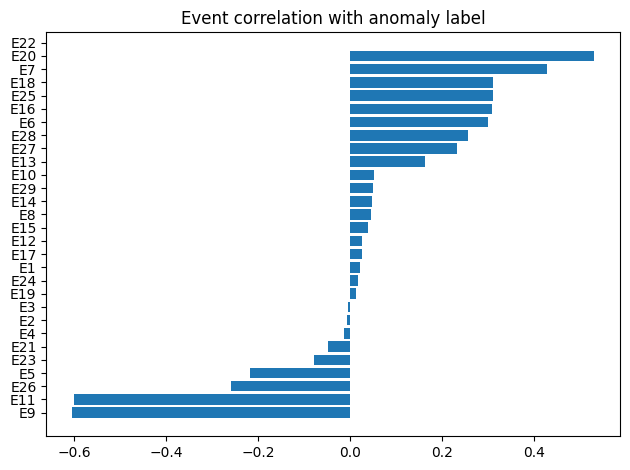

In [4]:
corr = train[event_columns + ['target']].corr()['target'].drop('target')
corr = corr.sort_values()
plt.barh(corr.index, corr.values)
plt.title('Event correlation with anomaly label')
plt.tight_layout()
plt.savefig(figures / 'event_label_correlation.png', dpi=160)
plt.show()


The template text gives a plain description for the events with the strongest correlation.

In [5]:
templates = pd.read_csv(raw / 'HDFS.log_templates.csv')
top_events = corr.abs().sort_values(ascending=False).head(6).index
top = templates[templates.EventId.isin(top_events)]
display(top)


,EventId,EventTemplate
6,E7,[*]writeBlock[*]received exception[*]
8,E9,[*]Received block[*]of size[*]from[*]
10,E11,[*]PacketResponder[*]for block[*]terminating[*]
17,E18,[*]Starting thread to transfer block[*]to[*]
19,E20,[*]Unexpected error trying to delete block[*]B...
24,E25,[*]BLOCK* ask[*]to replicate[*]to[*]


Logistic regression coefficients rank event counts after standardisation. A positive sign increases the anomaly score when other counts are held fixed.

In [6]:
scaler = StandardScaler()
X_train = scaler.fit_transform(train[event_columns])
y_train = train.target
model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=500)
model.fit(X_train, y_train)
coef = pd.DataFrame({'event': event_columns, 'coefficient': model.coef_[0]})
display(coef.reindex(coef.coefficient.abs().sort_values(ascending=False).index))


,event,coefficient
20,E21,12.044615
15,E16,-5.318854
22,E23,-3.616260
17,E18,2.615310
24,E25,2.615310
25,E26,-1.732779
8,E9,-1.620993
10,E11,-1.611755
26,E27,1.504630
5,E6,1.433840


PCA reduces the event-count space to components. The scree plot shows how much variation each component explains.

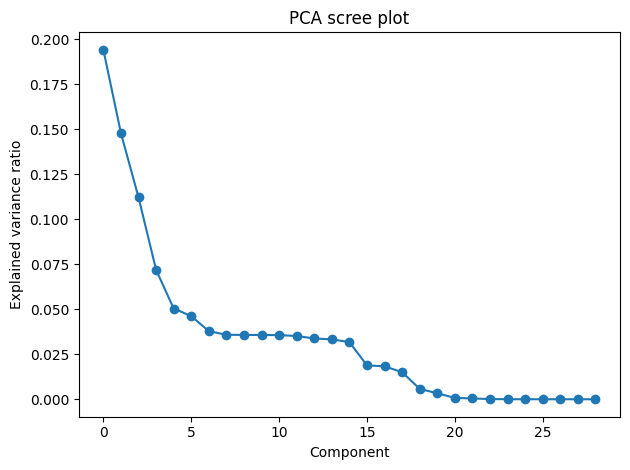

In [7]:
pca = PCA(random_state=42)
components = pca.fit_transform(X_train)
plt.plot(pca.explained_variance_ratio_, marker='o')
plt.title('PCA scree plot')
plt.xlabel('Component')
plt.ylabel('Explained variance ratio')
plt.tight_layout()
plt.savefig(figures / 'pca_scree_plot.png', dpi=160)
plt.show()


k-means is fitted to normal training blocks. The printed cluster rates show how anomalies fall near normal-behaviour groups.

In [8]:
normal_X = scaler.transform(normal)
model = KMeans(n_clusters=4, random_state=42, n_init=10)
model.fit(normal_X[:30000])
clusters = model.predict(X_train)
cluster_table = pd.DataFrame({'cluster': clusters, 'target': y_train})
display(cluster_table.groupby('cluster').target.agg(['size', 'mean']))


,size,mean
cluster,,
0,226269,0.019813
1,65914,0.059183
2,757,0.701453
3,52096,0.022804


The training-only summaries show which events differ by class. The following notebook uses validation data for model and threshold selection.